# Лабораторна робота 2. Проблеми багатозначного аналізу, варіант 15

**Динаміка пучка траєкторій моделі сервоприводу** (двигун постійного струму з керуванням по колу якоря).

Модель:
$$
J\ddot\theta + B\dot\theta = T,\qquad L_a\dot i_a + R_a i_a + e_m = e_a(t),\qquad e_m = K_1\dot\theta,\qquad T = K_2 i_a.
$$
Заміна $x_1=\theta,\ x_2=\dot\theta=\omega,\ x_3=i_a$ дає лінійну систему
$$
\dot x = Ax + f(t),\qquad
A=\begin{pmatrix}0&1&0\\0&-B/J&K_2/J\\0&-K_1/L_a&-R_a/L_a\end{pmatrix},\qquad
f(t)=\begin{pmatrix}0\\0\\e_a(t)/L_a\end{pmatrix}.
$$

Початковий стан відомий неточно: $x(0)\in M_0=\mathcal E(x_0,Q_0)=\{x:\langle Q_0^{-1}(x-x_0),x-x_0\rangle\le1\}$.
Перетин пучка траєкторій $X(t)=\bigcup_{x_0\in M_0}x(t,x_0,0)$ — це еліпсоїд
(Gianfortone 2018, §2.3.1; Kurzhanski–Varaiya 2000, леми 1.2–1.3):
$$
X(t)=\mathcal E\big(x(t),Q(t)\big),\qquad \dot Q = AQ+QA^*,\quad Q(0)=Q_0
\qquad\big(Q(t)=e^{At}Q_0e^{A^*t}\big).
$$

**План ноутбука**
1. Модель: $A$, $f$, спектр.
2. Рівняння Ляпунова: спільне інтегрування $x(t)$ і $Q(t)$.
3. Значення відображення $X(t)$: центр, півосі, $\det Q$, проєкції на осі.
4. Опорна функція і межі проєкцій.
5. Перевірки правильності.
6–7. Функції рисунків і «наочна» візуалізація вала.
8. Експерименти Е1–Е4, граничні стани, формула Ліувілля, анімація.

Рисунки і `report/figures/results.json` зберігаються для звіту (`report/report.typ`).
Комірки з позначкою `report` (розділи 1–5) потрапляють у додаток А звіту.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FFMpegWriter, FuncAnimation, PillowWriter
from matplotlib.patches import Wedge
from IPython.display import Video, display
from scipy.integrate import solve_ivp
from scipy.linalg import expm

FIG_DIR = os.path.abspath(os.path.join("report", "figures"))  # рисунки й results.json для звіту
os.makedirs(FIG_DIR, exist_ok=True)

N = 3  # розмірність фазового простору
LABELS = [r"$\theta$, рад", r"$\omega = \dot\theta$, рад/с", r"$i_a$, А"]
SHORT = [r"\theta", r"\omega", r"i_a"]
RTOL, ATOL = 1e-12, 1e-16  # точність інтегрування (див. перевірки в розділі 5)

## 1. Модель сервоприводу

Два набори умовних параметрів малого двигуна (СІ). Для сталої проти-ЕРС і сталої моменту в СІ $K_1=K_2$.

Перший стовпець $A$ нульовий, тому
$$
\det(sI-A)=s\,(s^2+a_1s+a_0),\qquad a_1=\frac BJ+\frac{R_a}{L_a},\qquad a_0=\frac{BR_a+K_1K_2}{JL_a}.
$$
* $\lambda_1=0$: кут **не стабілізується**, бо зворотного зв'язку за положенням немає;
* $\operatorname{Re}\lambda_{2,3}<0$: швидкість і струм загасають;
* $\operatorname{tr}A=-(B/J+R_a/L_a)<0$: система дисипативна;
* при $e_a=\mathrm{const}$: $\omega_\infty=K_2e_a/D$, $i_\infty=Be_a/D$, де $D=BR_a+K_1K_2$;
* лівий власний вектор для $\lambda_1=0$: $w=(1,\ JR_a/D,\ K_2L_a/D)^*$, і $e^{At}\to e_1w^*$ при $t\to\infty$.

In [2]:
# Набори параметрів (умовні значення для малого двигуна постійного струму).
#   P1 — власні числа A дійсні: 0, -1.18, -3.82 (аперіодичний перехідний процес);
#   P2 — мале тертя, більший K: 0, -1.1 ± 1.09i (коливальний процес).
PARAMS = {
    "P1": dict(J=0.01, B=0.01, K1=0.05, K2=0.05, Ra=2.0, La=0.5),
    "P2": dict(J=0.01, B=0.002, K1=0.1, K2=0.1, Ra=1.0, La=0.5),
}


def build_A(p):
    """Матриця A системи x' = A x + f(t)."""
    return np.array([
        [0.0, 1.0, 0.0],
        [0.0, -p["B"] / p["J"], p["K2"] / p["J"]],
        [0.0, -p["K1"] / p["La"], -p["Ra"] / p["La"]],
    ])


def build_f(p, ea):
    """Вектор-функція f(t) = (0, 0, ea(t)/La)*; ea — функція часу (напруга)."""
    return lambda t: np.array([0.0, 0.0, ea(t) / p["La"]])


def model_summary(p):
    """
    Характеристики моделі: власні числа A, слід, характеристичний многочлен
    s (s^2 + a1 s + a0) і коефіцієнт передачі напруги у встановлену швидкість
    ω∞ / ea = K2 / (B Ra + K1 K2) (при ea = const).
    """
    A = build_A(p)
    D = p["B"] * p["Ra"] + p["K1"] * p["K2"]
    a1 = p["B"] / p["J"] + p["Ra"] / p["La"]
    a0 = (p["B"] * p["Ra"] + p["K1"] * p["K2"]) / (p["J"] * p["La"])
    eig = np.linalg.eigvals(A)
    eig = eig[np.argsort(-eig.real)]
    return {
        "A": A.tolist(),
        "trace": float(np.trace(A)),
        "a1": a1, "a0": a0,
        "eig_re": eig.real.tolist(), "eig_im": eig.imag.tolist(),
        "speed_gain": p["K2"] / D,
        "current_gain": p["B"] / D,
        # лівий власний вектор для λ = 0 (w* A = 0, w_1 = 1): при ea = 0
        # Θ(t) -> e1 w*, тобто θ(∞) = <w, x0>, Q(∞) = <Q0 w, w> e1 e1*
        "w": [1.0, p["J"] * p["Ra"] / D, p["K2"] * p["La"] / D],
    }

In [3]:
# Модель і спектр для обох наборів параметрів
MODEL = {k: model_summary(p) for k, p in PARAMS.items()}
for k, p in PARAMS.items():
    s = MODEL[k]
    eig = ", ".join(f"{re:.4f}{im:+.4f}i" if abs(im) > 1e-12 else f"{re:.4f}"
                    for re, im in zip(s["eig_re"], s["eig_im"]))
    print(f"{k}: {p}\n    A = {np.round(build_A(p), 4).tolist()}\n    λ(A) = {eig},  "
          f"tr A = {s['trace']:.3f},  ω∞/ea = {s['speed_gain']:.4f},  w = {np.round(s['w'], 4).tolist()}")

P1: {'J': 0.01, 'B': 0.01, 'K1': 0.05, 'K2': 0.05, 'Ra': 2.0, 'La': 0.5}
    A = [[0.0, 1.0, 0.0], [0.0, -1.0, 5.0], [0.0, -0.1, -4.0]]
    λ(A) = 0.0000, -1.1771, -3.8229,  tr A = -5.000,  ω∞/ea = 2.2222,  w = [1.0, 0.8889, 1.1111]
P2: {'J': 0.01, 'B': 0.002, 'K1': 0.1, 'K2': 0.1, 'Ra': 1.0, 'La': 0.5}
    A = [[0.0, 1.0, 0.0], [0.0, -0.2, 10.0], [0.0, -0.2, -2.0]]
    λ(A) = 0.0000, -1.1000+1.0909i, -1.1000-1.0909i,  tr A = -2.200,  ω∞/ea = 8.3333,  w = [1.0, 0.8333, 4.1667]


## 2. Рівняння Ляпунова: спільне інтегрування $x(t)$ і $Q(t)$

Невідомі об'єднуємо у вектор $z=(x,\operatorname{vec}Q)\in\mathbb R^{3+9}$:
$$
\dot x = Ax+f(t),\qquad \dot Q = AQ+QA^*,\qquad x(0)=x_0,\ Q(0)=Q_0.
$$
Інтегруємо явним методом Рунге–Кутти 8-го порядку з автоматичним кроком (`solve_ivp`, `DOP853`, `rtol=1e-12`).
Через округлення $Q$ трохи втрачає симетричність, тому беремо $(Q+Q^*)/2$.

In [4]:
def bundle_rhs(t, z, A, f):
    """
    Права частина системи для z = (x, vec Q):
        x' = A x + f(t),   Q' = A Q + Q A*   (рівняння Ляпунова (7)).
    """
    x, Q = z[:N], z[N:].reshape(N, N)
    return np.concatenate([A @ x + f(t), (A @ Q + Q @ A.T).ravel()])


def solve_bundle(A, f, x0, Q0, T, n_t=601, extra_times=()):
    """
    Розв'язує задачу Коші для (x, Q) на [0, T] методом Рунге-Кутти 8-го порядку
    (DOP853) і повертає значення на сітці t (до сітки додаються extra_times).
    Через похибки округлення Q ледь втрачає симетричність, тому її симетризуємо.
    """
    t = np.union1d(np.linspace(0.0, T, n_t), np.asarray(extra_times, float))
    z0 = np.concatenate([np.asarray(x0, float), np.asarray(Q0, float).ravel()])
    sol = solve_ivp(bundle_rhs, (0.0, T), z0, method="DOP853", t_eval=t,
                    args=(A, f), rtol=RTOL, atol=ATOL)
    if not sol.success:
        raise RuntimeError(sol.message)
    x = sol.y[:N].T
    Q = sol.y[N:].T.reshape(-1, N, N)
    Q = 0.5 * (Q + Q.transpose(0, 2, 1))
    return {"t": sol.t, "x": x, "Q": Q, "nfev": int(sol.nfev)}


def at(sol, tk):
    """Індекс моменту tk у сітці розв'язку."""
    return int(np.argmin(np.abs(sol["t"] - tk)))

## 3. Значення багатозначного відображення $X(t)=\mathcal E(x(t),Q(t))$

Для кожного $t$:
* **центр** $x(t)$;
* **півосі** $a_k=\sqrt{\lambda_k(Q)}$ та їх напрямки (власні вектори $Q$);
* $\det Q$ і **об'єм** $\tfrac43\pi\sqrt{\det Q}$;
* **проєкції на осі**: $[x_i-\sqrt{Q_{ii}},\ x_i+\sqrt{Q_{ii}}]$ (опорна функція в напрямках $\pm e_i$).

In [5]:
def ellipsoid_info(x, Q):
    """
    Характеристики еліпсоїда E(x, Q): півосі sqrt(λ_k(Q)) та їх напрямки,
    det Q (об'єм E дорівнює 4/3 π sqrt(det Q)), число обумовленості Q і
    проєкції на осі — відрізки [x_i - sqrt(Q_ii), x_i + sqrt(Q_ii)]
    (опорна функція в напрямках ±e_i).
    """
    lam, vec = np.linalg.eigh(Q)
    half = np.sqrt(np.maximum(np.diag(Q), 0.0))
    return {
        "center": x.tolist(),
        "Q": Q.tolist(),
        "semi_axes": np.sqrt(np.maximum(lam[::-1], 0.0)).tolist(),
        "axes_dirs": vec[:, ::-1].T.tolist(),
        "det": float(np.linalg.det(Q)),
        "volume": float(4.0 / 3.0 * np.pi * np.sqrt(max(np.linalg.det(Q), 0.0))),
        "cond": float(lam[-1] / lam[0]),
        "lo": (x - half).tolist(),
        "hi": (x + half).tolist(),
    }


def value_table(sol, times):
    """Значення відображення X(t_k) у вибрані моменти часу."""
    return [{"t": float(sol["t"][at(sol, tk)])} | ellipsoid_info(sol["x"][at(sol, tk)],
                                                                 sol["Q"][at(sol, tk)])
            for tk in times]

## 4. Опорна функція і межа проєкцій

Опорна функція еліпсоїда і точка дотику опорної гіперплощини з нормаллю $\psi$ (градієнт опорної функції):
$$
c(\mathcal E(p,Q),\psi)=\langle p,\psi\rangle+\sqrt{\langle Q\psi,\psi\rangle},\qquad
x(\psi)=p+\frac{Q\psi}{\sqrt{\langle Q\psi,\psi\rangle}}.
$$
**Межа проєкції на площину $(x_i,x_j)$.** Беремо $\psi$ з нулями поза координатами $i,j$; проєкції точок $x(\psi)$ лягають на межу еліпса
$\mathcal E(Pp,PQP^*)$. Щоб точки йшли рівномірно і для дуже витягнутих еліпсів, беремо
$\psi=M^{-1}Lu$, де $M=PQP^*=LL^*$ (Холецький), $u=(\cos\varphi,\sin\varphi)$. Тоді $\langle M\psi,\psi\rangle=1$ і проєкція точки дорівнює $Pp+Lu$.

Оскільки $n=3$, еліпсоїд можна намалювати і цілком: $x+Q^{1/2}u$, $\|u\|=1$.

In [6]:
def support(x, Q, psi):
    """Опорна функція еліпсоїда: c(E(x, Q), ψ) = <x, ψ> + sqrt(<Qψ, ψ>)."""
    return psi @ x + np.sqrt(np.einsum("...i,ij,...j->...", psi, Q, psi))


def boundary_point(x, Q, psi):
    """
    Точка дотику опорної гіперплощини з нормаллю ψ (градієнт опорної функції):
        x(ψ) = x + Q ψ / sqrt(<Qψ, ψ>).
    """
    Qpsi = psi @ Q
    return x + Qpsi / np.sqrt(np.sum(Qpsi * psi, axis=-1, keepdims=True))


def boundary_2d(x, Q, i, j, m=240):
    """
    Межа ортогональної проєкції E(x, Q) на площину (x_i, x_j): ψ пробігає
    напрямки цієї площини (решта координат ψ — нулі), і проєкція точки
    дотику x(ψ) на площину лежить на межі проєкції еліпсоїда.
    Напрямки ψ беремо не рівномірно по колу, а ψ = M^{-1} L u, де M — блок Q
    на площині (i, j), M = L L*, u = (cos φ, sin φ): тоді точки x(ψ) = x + L u
    розподілені вздовж межі рівномірно і для дуже витягнутих еліпсів.
    """
    phi = np.linspace(0.0, 2 * np.pi, m)
    M = Q[np.ix_([i, j], [i, j])]
    L = np.linalg.cholesky(M)
    psi2 = np.linalg.solve(M, L @ np.array([np.cos(phi), np.sin(phi)])).T
    psi = np.zeros((m, N))
    psi[:, i], psi[:, j] = psi2[:, 0], psi2[:, 1]
    pts = boundary_point(x, Q, psi)
    return pts[:, i], pts[:, j]


def ellipsoid_surface(x, Q, m=40):
    """Поверхня тривимірного еліпсоїда: x + Q^{1/2} u, де |u| = 1."""
    lam, vec = np.linalg.eigh(Q)
    S = vec @ np.diag(np.sqrt(np.maximum(lam, 0.0))) @ vec.T  # Q^{1/2}
    u, v = np.meshgrid(np.linspace(0, 2 * np.pi, m), np.linspace(0, np.pi, m // 2))
    U = np.stack([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)], axis=-1)
    P = x + U @ S.T
    return P[..., 0], P[..., 1], P[..., 2]

## 5. Перевірки правильності

* **(a)** $Q(t)$ з рівняння Ляпунова порівнюється з явною формулою $e^{At}Q_0e^{A^*t}$.
* **(b)** $\det Q(t)$ порівнюється з формулою Ліувілля: $\det Q(t)=\det Q_0\,e^{2t\operatorname{tr}A}$,
  бо $\det e^{At}=\prod_k e^{\lambda_kt}=e^{t\operatorname{tr}A}$.
* **(c)** Центр порівнюється з окремо розв'язаною задачею Коші для $x$.
* **(d)** Монте-Карло: 300 точок усередині $M_0$ і 300 на межі інтегруються окремо. Тоді
  $\langle Q^{-1}(x-x(t)),x-x(t)\rangle\le1$ для внутрішніх точок і $=1$ для граничних (лінійне відображення переводить межу в межу).

*Обумовленість.* Півосі загасають з різною швидкістю, тож $\operatorname{cond}Q(t)$ росте експоненційно.
Відносна точність найменшої півосі і $\det Q$ має порядок $10^{-16}\operatorname{cond}Q$, тому горизонти вибрано так, щоб $\operatorname{cond}Q(T)\lesssim10^{14}$.

In [7]:
def sample_ellipsoid(x0, Q0, m, rng, on_boundary=False):
    """
    Випадкові точки еліпсоїда E(x0, Q0) = x0 + Q0^{1/2} K, K — одинична куля:
    рівномірно у кулі (або на сфері, якщо on_boundary) і лінійне перетворення.
    """
    u = rng.standard_normal((m, N))
    u /= np.linalg.norm(u, axis=1, keepdims=True)
    if not on_boundary:
        u *= rng.random((m, 1)) ** (1.0 / N)
    lam, vec = np.linalg.eigh(Q0)
    S = vec @ np.diag(np.sqrt(lam)) @ vec.T
    return x0 + u @ S.T


def simulate_samples(A, f, X0, t):
    """Траєкторії x' = A x + f(t) для набору початкових точок X0 (m×3) одночасно."""
    m = len(X0)

    def rhs(tt, z):
        X = z.reshape(m, N)
        return (X @ A.T + f(tt)).ravel()

    sol = solve_ivp(rhs, (t[0], t[-1]), X0.ravel(), method="DOP853", t_eval=t,
                    rtol=RTOL, atol=1e-14)
    return sol.y.T.reshape(len(t), m, N)  # [момент, траєкторія, координата]


def quad_form(sol, traj):
    """<Q(t)^{-1}(x - x(t)), x - x(t)> для всіх моментів і траєкторій."""
    d = traj - sol["x"][:, None, :]
    w = np.linalg.solve(sol["Q"], d.transpose(0, 2, 1)).transpose(0, 2, 1)
    return np.sum(w * d, axis=-1)


def checks(A, f, x0, Q0, sol, rng, m=300):
    """
    (a) Q(t) з рівняння Ляпунова проти явної формули Θ(t) Q0 Θ*(t), Θ = exp(A t);
    (b) det Q(t) проти формули Ліувілля det Q0 · exp(2 tr A · t);
    (c) центр x(t) проти окремо розв'язаної задачі Коші для x;
    (d) вибіркові траєкторії: точки зсередини M0 лишаються в X(t), точки межі —
        на межі (квадратична форма <Q^{-1}(x - x(t)), x - x(t)> ≤ 1 та = 1).
    """
    t = sol["t"]
    Th = np.array([expm(A * tk) for tk in t])
    Q_ex = Th @ Q0 @ Th.transpose(0, 2, 1)
    err_Q = np.linalg.norm(sol["Q"] - Q_ex, axis=(1, 2)) / np.linalg.norm(Q_ex, axis=(1, 2))
    det_ode = np.linalg.det(sol["Q"])
    det_liouv = np.linalg.det(Q0) * np.exp(2 * np.trace(A) * t)
    err_det = np.abs(det_ode - det_liouv) / det_liouv
    cond = np.array([np.linalg.cond(Q) for Q in sol["Q"]])
    xc = simulate_samples(A, f, np.asarray(x0, float)[None, :], t)[:, 0, :]
    err_x = np.max(np.abs(xc - sol["x"]))
    inner = simulate_samples(A, f, sample_ellipsoid(x0, Q0, m, rng), t)
    bound = simulate_samples(A, f, sample_ellipsoid(x0, Q0, m, rng, on_boundary=True), t)
    q_in, q_bd = quad_form(sol, inner), quad_form(sol, bound)
    return {
        "err_Q_max": float(err_Q.max()),
        "err_det_max": float(err_det.max()),
        "err_det_T": float(err_det[-1]),
        "cond_T": float(cond[-1]),
        "err_x_max": float(err_x),
        "inner_q_max": float(q_in.max()),
        "bound_q_min": float(q_bd.min()),
        "bound_q_max": float(q_bd.max()),
        "n_samples": m,
        # для рисунків
        "_inner": inner, "_bound": bound, "_det_ode": det_ode, "_det_liouv": det_liouv,
        "_err_det": err_det, "_cond": cond,
    }

## 6. Функції для рисунків

* `plot_bands`: проєкції графіка $\operatorname{gr}X=\{(t,x):x\in X(t)\}$ на площини $(t,x_i)$, тобто смуги $x_i\pm\sqrt{Q_{ii}}$ з вибірковими траєкторіями;
* `plot_sections`: перерізи $X(t_k)$ на координатних площинах;
* `plot_tube`: проєкція графіка на $(t,x_i,x_j)$ («труба»);
* `plot_ellipsoids_3d`: еліпсоїди $X(t_k)$ цілком;
* `plot_det`: $\det Q$ проти формули Ліувілля;
* `plot_compare_params`: порівняння наборів параметрів (Е4).

In [8]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
})
CMAP = plt.cm.viridis


def save(fig, name):
    """Зберігає рисунок для звіту (report/figures/) і показує його в ноутбуці."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_bands(sol, chk, name, title, n_show=25):
    """
    Проєкції графіка gr X = {(t, x): x ∈ X(t)} на площини (t, x_i): смуги
    x_i(t) ± sqrt(Q_ii(t)), центр і кілька вибіркових траєкторій з M0.
    """
    t, x, Q = sol["t"], sol["x"], sol["Q"]
    fig, axs = plt.subplots(N, 1, figsize=(9, 8.2), sharex=True)
    for i, ax in enumerate(axs):
        h = np.sqrt(Q[:, i, i])
        ax.fill_between(t, x[:, i] - h, x[:, i] + h, color="tab:blue", alpha=0.25,
                        label=r"проєкція $X(t)$")
        ax.plot(t, x[:, i] - h, color="tab:blue", lw=1)
        ax.plot(t, x[:, i] + h, color="tab:blue", lw=1)
        ax.plot(t, chk["_bound"][:, :n_show, i], color="tab:orange", lw=0.6, alpha=0.7)
        ax.plot(t, chk["_inner"][:, :n_show, i], color="tab:gray", lw=0.5, alpha=0.6)
        ax.plot(t, x[:, i], "k", lw=1.8, label=r"центр $x(t)$")
        ax.set_ylabel(LABELS[i])
    axs[0].plot([], [], color="tab:orange", lw=1, label="траєкторії з межі $M_0$")
    axs[0].plot([], [], color="tab:gray", lw=1, label="траєкторії зсередини $M_0$")
    axs[0].legend(fontsize=8, ncol=2, loc="best")
    axs[-1].set_xlabel(r"$t$, с")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    save(fig, name)


def plot_sections(sol, chk, times, pairs, name, title):
    """
    Перерізи X(t_k) у проєкціях на координатні площини (межа — за формулою точки
    дотику), траєкторія центру і положення вибіркових точок у моменти t_k.
    """
    fig, axs = plt.subplots(1, len(pairs), figsize=(5.2 * len(pairs), 4.9))
    colors = CMAP(np.linspace(0, 0.9, len(times)))
    for ax, (i, j) in zip(np.atleast_1d(axs), pairs):
        ax.plot(sol["x"][:, i], sol["x"][:, j], "k--", lw=1, label="центр $x(t)$")
        for tk, c in zip(times, colors):
            k = at(sol, tk)
            bi, bj = boundary_2d(sol["x"][k], sol["Q"][k], i, j)
            ax.plot(bi, bj, color=c, lw=1.8, label=f"$t = {sol['t'][k]:g}$")
            ax.fill(bi, bj, color=c, alpha=0.12)
            ax.scatter(chk["_inner"][k, :, i], chk["_inner"][k, :, j], s=2, color=c, alpha=0.5)
        ax.set_xlabel(LABELS[i])
        ax.set_ylabel(LABELS[j])
    np.atleast_1d(axs)[0].legend(fontsize=7.5, loc="best")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    save(fig, name)


def plot_tube(sol, i, j, times, name, title, n_sec=150):
    """Проєкція графіка на (t, x_i, x_j): «труба» з перерізів X(t)."""
    fig = plt.figure(figsize=(9, 6.2))
    ax = fig.add_subplot(projection="3d")
    ks = np.linspace(0, len(sol["t"]) - 1, n_sec).astype(int)
    rings = [boundary_2d(sol["x"][k], sol["Q"][k], i, j, m=80) for k in ks]
    Ti = np.repeat(sol["t"][ks][:, None], 80, axis=1)
    Bi = np.array([r[0] for r in rings])
    Bj = np.array([r[1] for r in rings])
    ax.plot_surface(Ti, Bi, Bj, color="tab:blue", alpha=0.22, linewidth=0)
    for tk, c in zip(times, CMAP(np.linspace(0, 0.9, len(times)))):
        k = at(sol, tk)
        bi, bj = boundary_2d(sol["x"][k], sol["Q"][k], i, j)
        ax.plot(np.full_like(bi, sol["t"][k]), bi, bj, color=c, lw=2)
    ax.plot(sol["t"], sol["x"][:, i], sol["x"][:, j], "k", lw=1.5)
    ax.set_xlabel(r"$t$, с")
    ax.set_ylabel(LABELS[i])
    ax.set_zlabel(LABELS[j])
    ax.view_init(elev=22, azim=-60)
    ax.set_title(title, fontsize=11)
    fig.tight_layout()
    save(fig, name)


def plot_ellipsoids_3d(sol, chk, times, name, title):
    """Еліпсоїди X(t_k) у фазовому просторі (θ, ω, i_a) цілком (n = 3)."""
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(projection="3d")
    for tk, c in zip(times, CMAP(np.linspace(0, 0.9, len(times)))):
        k = at(sol, tk)
        X, Y, Z = ellipsoid_surface(sol["x"][k], sol["Q"][k])
        ax.plot_surface(X, Y, Z, color=c, alpha=0.35, linewidth=0)
        ax.plot_wireframe(X, Y, Z, color=c, lw=0.3, alpha=0.5, rstride=4, cstride=4)
        p = chk["_bound"][k, :120]
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=3, color="k", alpha=0.6)
        ax.text(*sol["x"][k], f"  t={sol['t'][k]:g}", fontsize=8)
    ax.plot(*sol["x"].T, "k--", lw=1)
    ax.set_xlabel(LABELS[0])
    ax.set_ylabel(LABELS[1])
    ax.set_zlabel(LABELS[2])
    ax.view_init(elev=20, azim=-55)
    ax.set_title(title, fontsize=11)
    fig.tight_layout()
    save(fig, name)


def plot_det(cases, name):
    """det Q(t) з рівняння Ляпунова і за формулою Ліувілля; відносна похибка й cond Q."""
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
    for (lab, sol, chk), c in zip(cases, plt.cm.tab10(np.arange(len(cases)))):
        axs[0].semilogy(sol["t"], chk["_det_ode"], color=c, lw=2.5, alpha=0.6,
                        label=rf"{lab}: $\det Q(t)$ (рівняння Ляпунова)")
        axs[0].semilogy(sol["t"], chk["_det_liouv"], "k:", lw=1.3)
        axs[1].semilogy(sol["t"], np.maximum(chk["_err_det"], 1e-17), color=c, lw=1.5,
                        label=f"{lab}: відносна похибка det")
        axs[1].semilogy(sol["t"], chk["_cond"] * 1e-16, color=c, lw=1, ls="--",
                        label=rf"{lab}: $10^{{-16}}\cdot\mathrm{{cond}}\,Q(t)$")
    axs[0].plot([], [], "k:", label=r"Ліувілль: $\det Q_0\, e^{2\,\mathrm{tr}A\, t}$")
    axs[0].set_xlabel(r"$t$, с")
    axs[0].set_title(r"Спадання $\det Q(t)$ (об'єм пучка $\sim\sqrt{\det Q}$)")
    axs[0].legend(fontsize=8)
    axs[1].set_xlabel(r"$t$, с")
    axs[1].set_title("Точність det Q і обумовленість Q")
    axs[1].legend(fontsize=7.5)
    fig.tight_layout()
    save(fig, name)


def plot_compare_params(sols, times, name):
    """Е4: перерізи X(t) у площині (ω, i_a) для двох наборів параметрів."""
    fig, axs = plt.subplots(1, len(sols), figsize=(6 * len(sols), 5.2))
    for ax, (lab, sol) in zip(axs, sols):
        ax.plot(sol["x"][:, 1], sol["x"][:, 2], "k--", lw=1)
        for tk, c in zip(times, CMAP(np.linspace(0, 0.9, len(times)))):
            k = at(sol, tk)
            bi, bj = boundary_2d(sol["x"][k], sol["Q"][k], 1, 2)
            ax.plot(bi, bj, color=c, lw=1.8, label=f"$t = {sol['t'][k]:g}$")
            ax.fill(bi, bj, color=c, alpha=0.12)
            ax.plot(*sol["x"][k, 1:], "o", color=c, ms=4)
        ax.set_xlabel(LABELS[1])
        ax.set_ylabel(LABELS[2])
        ax.set_title(lab, fontsize=11)
    axs[0].legend(fontsize=8)
    fig.tight_layout()
    save(fig, name)

## 7. «Наочна» візуалізація: вал сервоприводу

Вал у момент $t_k$:
* **сектор** — множина можливих кутів $[\theta-\sqrt{Q_{11}},\ \theta+\sqrt{Q_{11}}]$ (проєкція $X(t_k)$ на вісь $\theta$);
* **стрілка** — кут центру пучка;
* під валом — відрізки можливих швидкостей і струмів.

In [9]:
def draw_shaft(ax, sol, k, w_max, i_max):
    """
    Вал у момент t_k: сектор можливих кутів [θ - sqrt(Q11), θ + sqrt(Q11)]
    (проєкція X(t) на вісь θ), стрілка — кут центру θ(t); під валом — відрізки
    можливих швидкостей і струмів (проєкції X(t) на осі ω та i_a).
    """
    ax.clear()
    ax.set_aspect("equal")
    ax.axis("off")
    th, w, ia = sol["x"][k]
    h = np.sqrt(np.diag(sol["Q"][k]))
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, lw=1.2, color="0.4"))
    for a in np.arange(0, 360, 30):  # шкала через 30°
        r = np.radians(a)
        ax.plot([0.92 * np.cos(r), np.cos(r)], [0.92 * np.sin(r), np.sin(r)], color="0.5", lw=0.8)
    span = min(np.degrees(2 * h[0]), 359.9)
    a0 = np.degrees(th) - span / 2
    ax.add_patch(Wedge((0, 0), 1, a0, a0 + span, color="tab:blue", alpha=0.35))
    ax.annotate("", (0.9 * np.cos(th), 0.9 * np.sin(th)), (0, 0),
                arrowprops=dict(arrowstyle="-|>", color="k", lw=2))
    ax.add_patch(plt.Circle((0, 0), 0.08, color="k"))
    # шкали швидкості та струму: відрізок [центр ± піввісь] на відрізку [-max, max]
    for y, c, hw, mx, lab in [(-1.35, w, h[1], w_max, r"$\omega$"),
                              (-1.65, ia, h[2], i_max, r"$i_a$")]:
        ax.plot([-1, 1], [y, y], color="0.6", lw=1)
        ax.plot([0, 0], [y - 0.05, y + 0.05], color="0.6", lw=1)
        ax.plot([(c - hw) / mx, (c + hw) / mx], [y, y], color="tab:blue", lw=5, alpha=0.6)
        ax.plot(c / mx, y, "k|", ms=9, mew=2)
        ax.text(-1.12, y, lab, ha="right", va="center", fontsize=9)
        ax.text(1.04, y, f"±{mx:.2g}", ha="left", va="center", fontsize=6.5, color="0.4")
    ax.set_xlim(-1.35, 1.4)
    ax.set_ylim(-1.8, 1.1)
    ax.set_title(rf"$t = {sol['t'][k]:.2f}$: $\theta \in [{th - h[0]:.2f},\ {th + h[0]:.2f}]$",
                 fontsize=9)


def shaft_scales(sol):
    """Масштаби шкал швидкості й струму (максимум по часу модуля меж проєкцій)."""
    h = np.sqrt(np.einsum("kii->ki", sol["Q"]))
    return (np.max(np.abs(sol["x"][:, 1]) + h[:, 1]) * 1.05,
            np.max(np.abs(sol["x"][:, 2]) + h[:, 2]) * 1.05)


def plot_shaft_frames(sol, times, name, title):
    """Кінострічка: стан вала й множина можливих станів у моменти t_k."""
    w_max, i_max = shaft_scales(sol)
    cols = 4
    rows = int(np.ceil(len(times) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(3.3 * cols, 3.6 * rows))
    for ax, tk in zip(axs.ravel(), times):
        draw_shaft(ax, sol, at(sol, tk), w_max, i_max)
    for ax in axs.ravel()[len(times):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    save(fig, name)


def make_shaft_animation(sol, ea, base, fps=20, stride=3):
    """
    Анімація: (зліва) вал з сектором можливих кутів і шкалами ω, i_a;
    (посередині) переріз X(t) у площині (θ, ω) з траєкторією центру;
    (справа) смуга θ(t) ± sqrt(Q11) і напруга e_a(t).
    """
    w_max, i_max = shaft_scales(sol)
    t, x, Q = sol["t"], sol["x"], sol["Q"]
    h = np.sqrt(np.einsum("kii->ki", Q))
    fig, axs = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.15, 1.3]})
    ax1, ax2 = axs[1], axs[2]
    ax1.set_xlim((x[:, 0] - h[:, 0]).min() - 0.1, (x[:, 0] + h[:, 0]).max() + 0.1)
    ax1.set_ylim((x[:, 1] - h[:, 1]).min() - 0.2, (x[:, 1] + h[:, 1]).max() + 0.2)
    ax1.set_xlabel(LABELS[0])
    ax1.set_ylabel(LABELS[1])
    ax1.set_title(r"Переріз $X(t)$ у площині $(\theta, \omega)$")
    (path,) = ax1.plot([], [], "k--", lw=1)
    (ell,) = ax1.plot([], [], color="tab:blue", lw=2)
    ax2.fill_between(t, x[:, 0] - h[:, 0], x[:, 0] + h[:, 0], color="tab:blue", alpha=0.15)
    ax2.plot(t, x[:, 0], "k", lw=1)
    ax2.set_xlabel(r"$t$, с")
    ax2.set_ylabel(LABELS[0])
    ax2.set_title(r"Проєкція графіка на $(t, \theta)$ і напруга $e_a(t)$")
    ax2b = ax2.twinx()
    ax2b.plot(t, [ea(tt) for tt in t], color="tab:red", lw=1, alpha=0.6)
    ax2b.set_ylabel(r"$e_a$, В", color="tab:red")
    ax2b.grid(False)
    cursor = ax2.axvline(0, color="tab:orange", lw=1.5)
    frames = list(range(0, len(t), stride)) + [len(t) - 1] * fps

    def update(k):
        draw_shaft(axs[0], sol, k, w_max, i_max)
        path.set_data(x[: k + 1, 0], x[: k + 1, 1])
        bi, bj = boundary_2d(x[k], Q[k], 0, 1)
        ell.set_data(bi, bj)
        cursor.set_xdata([t[k], t[k]])
        return [path, ell, cursor]

    fig.tight_layout()
    anim = FuncAnimation(fig, update, frames=frames, blit=False)
    anim.save(os.path.join(FIG_DIR, base + ".gif"), writer=PillowWriter(fps=fps), dpi=70)
    anim.save(os.path.join(FIG_DIR, base + ".mp4"), writer=FFMpegWriter(fps=fps, bitrate=2400),
              dpi=110)
    plt.close(fig)
    print(f"  збережено {base}.gif / {base}.mp4")

## 8. Обчислювальні експерименти

Допоміжні функції: друк таблиць, `run(...)` (один експеримент: розв'язок, значення відображення, перевірки), `cov_matrix`.
Генератор випадкових чисел фіксовано (`seed=15`), тому результати відтворювані.

In [10]:
def public(chk):
    """Числові результати перевірок без масивів для рисунків."""
    return {k: v for k, v in chk.items() if not k.startswith("_")}


def print_table(rows):
    print(f"{'t':>5} | {'центр x(t)':^32} | {'півосі':^30} | {'det Q':>9}")
    for r in rows:
        c = " ".join(f"{v:10.4f}" for v in r["center"])
        s = " ".join(f"{v:9.2e}" for v in r["semi_axes"])
        print(f"{r['t']:5.2f} | {c} | {s} | {r['det']:9.2e}")


def print_checks(chk):
    print(f"  (a) max ||Q - ΘQ0Θ*|| / ||ΘQ0Θ*||            = {chk['err_Q_max']:.1e}")
    print(f"  (b) відн. похибка det Q (Ліувілль): max {chk['err_det_max']:.1e}, "
          f"при t = T {chk['err_det_T']:.1e} (cond Q(T) = {chk['cond_T']:.1e})")
    print(f"  (c) max |x(t) - x_окремо(t)|                 = {chk['err_x_max']:.1e}")
    print(f"  (d) {chk['n_samples']} траєкторій зсередини M0: max <Q^-1 d, d> = "
          f"{chk['inner_q_max']:.6f};  з межі: [{chk['bound_q_min']:.10f}, "
          f"{chk['bound_q_max']:.10f}]")


def run(label, p, ea, x0, Q0, T, times, rng):
    """Один експеримент: розв'язок, значення відображення, перевірки."""
    A, f = build_A(p), build_f(p, ea)
    sol = solve_bundle(A, f, x0, Q0, T, extra_times=times)
    chk = checks(A, f, np.asarray(x0, float), np.asarray(Q0, float), sol, rng)
    rows = value_table(sol, times)
    print(f"\n{label}:  T = {T}, nfev = {sol['nfev']}")
    print_table(rows)
    print_checks(chk)
    return sol, chk, rows


def cov_matrix(std, corr):
    """Q0 = D R D: std — півосі проєкцій (sqrt(Q_ii)), corr — матриця кореляцій."""
    D = np.diag(std)
    return D @ np.asarray(corr, float) @ D


rng = np.random.default_rng(15)
OUT = {"params": PARAMS, "model": MODEL, "rtol": RTOL, "atol": ATOL}  # усе, що читає звіт
zero = lambda t: 0.0
Q0_ball = 0.3 ** 2 * np.eye(N)

### Е1. Вільний вибіг вала

$e_a=0$, параметри P1. Вал обертається зі швидкістю, відомою наближено: $x_0=(0,5,0)$, $Q_0=0.3^2I$ (куля), $T=3$ с.

Очікувано: $\omega$ та $i_a$ загасають, невизначеність за ними зменшується, а невизначеність **кута росте**, бо в кут інтегрується невідома швидкість. Еліпсоїд витягується вздовж $\theta$ і сплющується.

In [11]:
x0_e1 = [0.0, 5.0, 0.0]
T1, times1 = 3.0, [0.0, 0.25, 0.5, 1.0, 2.0, 3.0]
s1, c1, r1 = run("Е1. Вільний вибіг (P1, ea = 0)", PARAMS["P1"], zero, x0_e1, Q0_ball,
                 T1, times1, rng)


Е1. Вільний вибіг (P1, ea = 0):  T = 3.0, nfev = 1241
    t |            центр x(t)            |             півосі             |     det Q
 0.00 |     0.0000     5.0000     0.0000 |  3.00e-01  3.00e-01  3.00e-01 |  7.29e-04
 0.25 |     1.1015     3.8460    -0.0681 |  3.46e-01  2.75e-01  8.12e-02 |  5.98e-05
 0.50 |     1.9416     2.9119    -0.0770 |  3.75e-01  2.35e-01  2.52e-02 |  4.91e-06
 1.00 |     3.0498     1.6367    -0.0541 |  4.19e-01  1.38e-01  3.14e-03 |  3.31e-08
 2.00 |     4.0141     0.5065    -0.0179 |  4.83e-01  3.93e-02  6.47e-05 |  1.50e-12
 3.00 |     4.3118     0.1561    -0.0055 |  5.09e-01  1.15e-02  1.41e-06 |  6.82e-17
  (a) max ||Q - ΘQ0Θ*|| / ||ΘQ0Θ*||            = 2.9e-13
  (b) відн. похибка det Q (Ліувілль): max 4.1e-07, при t = T 8.2e-08 (cond Q(T) = 1.3e+11)
  (c) max |x(t) - x_окремо(t)|                 = 3.7e-13
  (d) 300 траєкторій зсередини M0: max <Q^-1 d, d> = 0.999207;  з межі: [0.9999997082, 1.0000004374]


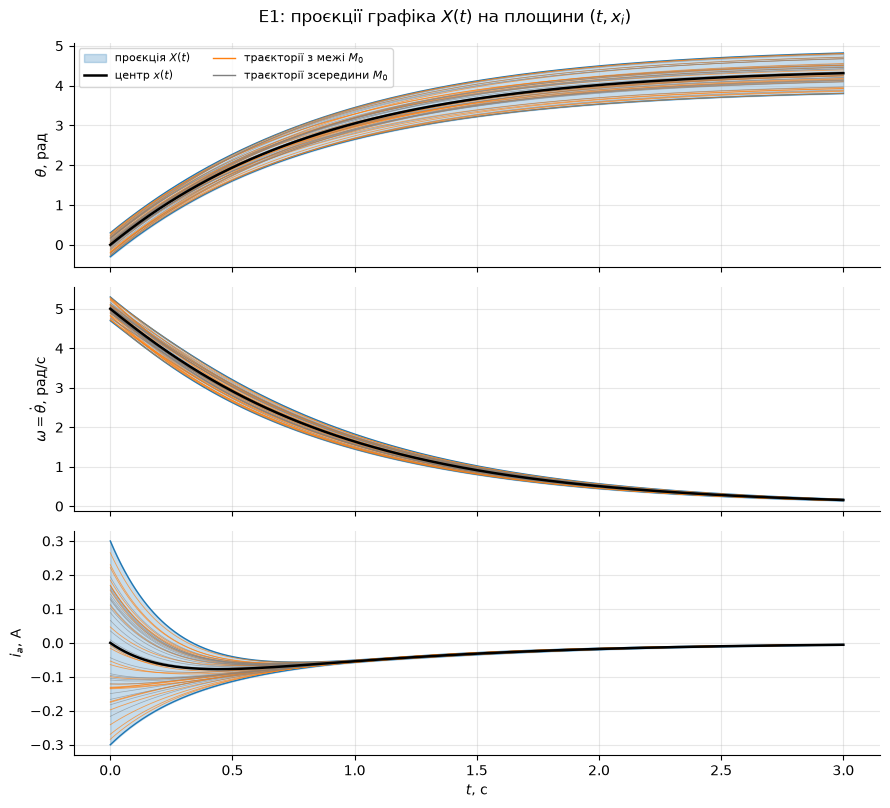

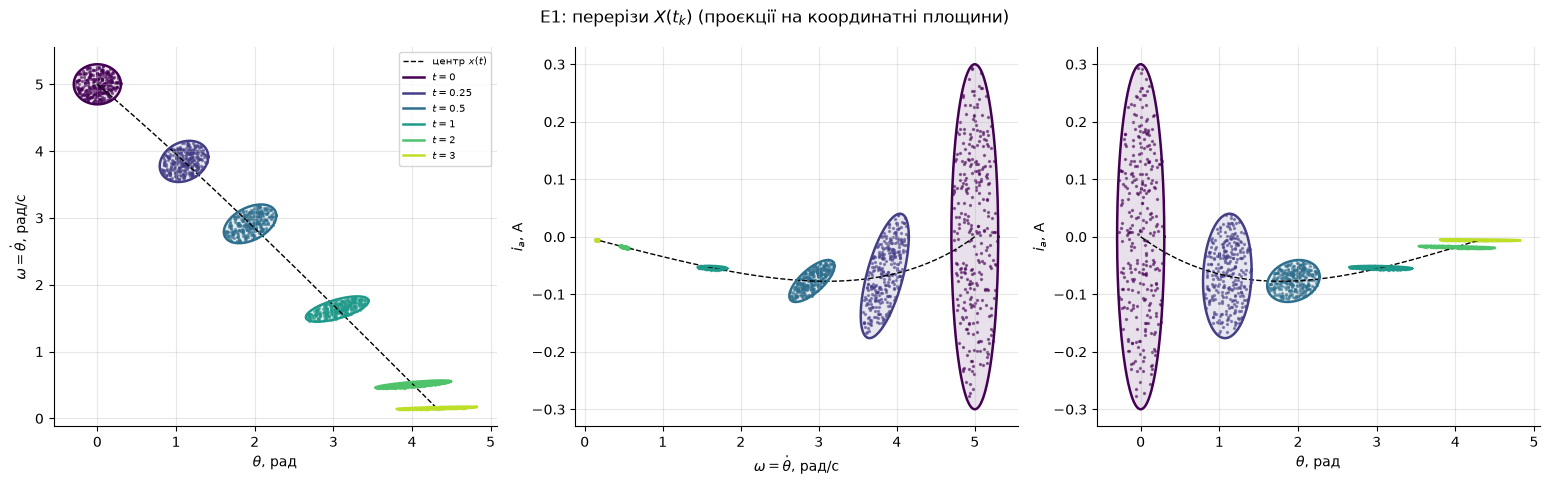

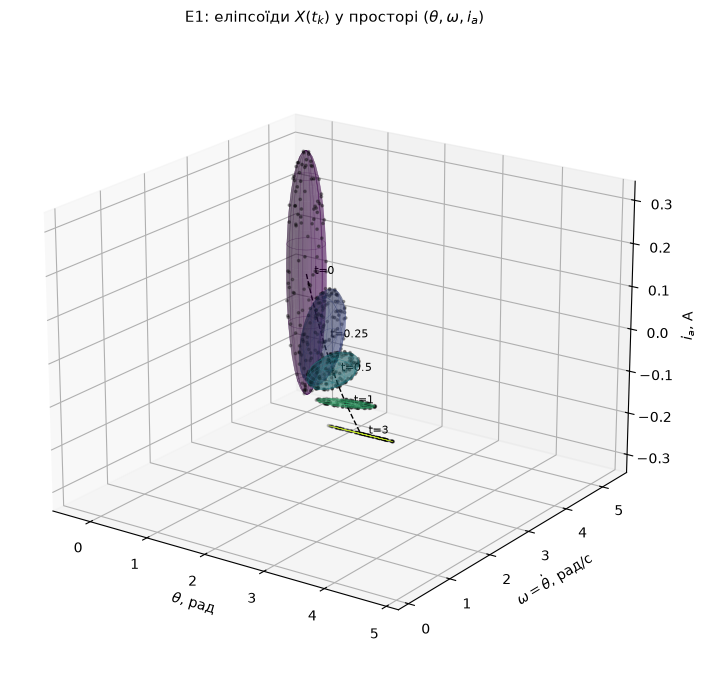

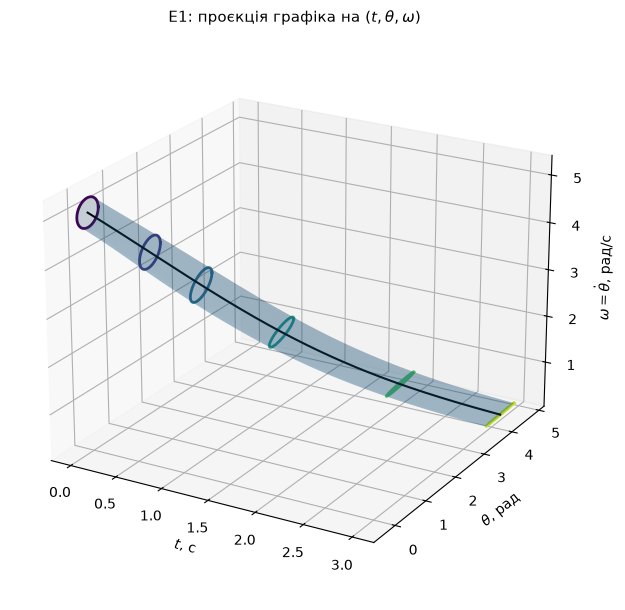

In [12]:
plot_bands(s1, c1, "e1_bands.png", r"Е1: проєкції графіка $X(t)$ на площини $(t, x_i)$")
plot_sections(s1, c1, times1, [(0, 1), (1, 2), (0, 2)], "e1_sections.png",
              r"Е1: перерізи $X(t_k)$ (проєкції на координатні площини)")
plot_ellipsoids_3d(s1, c1, [0.0, 0.25, 0.5, 1.0, 3.0], "e1_ellipsoids3d.png",
                   r"Е1: еліпсоїди $X(t_k)$ у просторі $(\theta, \omega, i_a)$")
plot_tube(s1, 0, 1, times1, "e1_tube.png", r"Е1: проєкція графіка на $(t, \theta, \omega)$")

### Е2. Сталий вхід $e_a=6$ В

Той самий $Q_0$, старт зі спокою ($x_0=0$). Центр виходить на $\omega_\infty=K_2e_a/D$, $i_\infty=Be_a/D$, кут росте лінійно.

**Ключове:** $Q(t)$ не залежить від $f$, тобто від напруги. Отже $Q_{Е2}(t)=Q_{Е1}(t)$: напруга лише зсуває пучок, а форма його та сама.


Е2. Сталий вхід (P1, ea = 6 В):  T = 3.0, nfev = 1241
    t |            центр x(t)            |             півосі             |     det Q
 0.00 |     0.0000     0.0000     0.0000 |  3.00e-01  3.00e-01  3.00e-01 |  7.29e-04
 0.25 |     0.1160     1.2604     1.8873 |  3.46e-01  2.75e-01  8.12e-02 |  5.98e-05
 0.50 |     0.7079     3.5158     2.5503 |  3.75e-01  2.35e-01  2.52e-02 |  4.91e-06
 1.00 |     3.5282     7.5261     2.8038 |  4.19e-01  1.38e-01  3.14e-03 |  3.31e-08
 2.00 |    13.4054    11.5066     2.7299 |  4.83e-01  3.93e-02  6.47e-05 |  1.50e-12
 3.00 |    25.6641    12.7696     2.6866 |  5.09e-01  1.15e-02  1.41e-06 |  6.82e-17
  (a) max ||Q - ΘQ0Θ*|| / ||ΘQ0Θ*||            = 2.9e-13
  (b) відн. похибка det Q (Ліувілль): max 4.1e-07, при t = T 8.2e-08 (cond Q(T) = 1.3e+11)
  (c) max |x(t) - x_окремо(t)|                 = 2.1e-11
  (d) 300 траєкторій зсередини M0: max <Q^-1 d, d> = 0.996843;  з межі: [0.9999887107, 1.0000106422]
  max |Q_Е1(t) - Q_Е2(t)| = 2.2e-14;  ω∞ = 

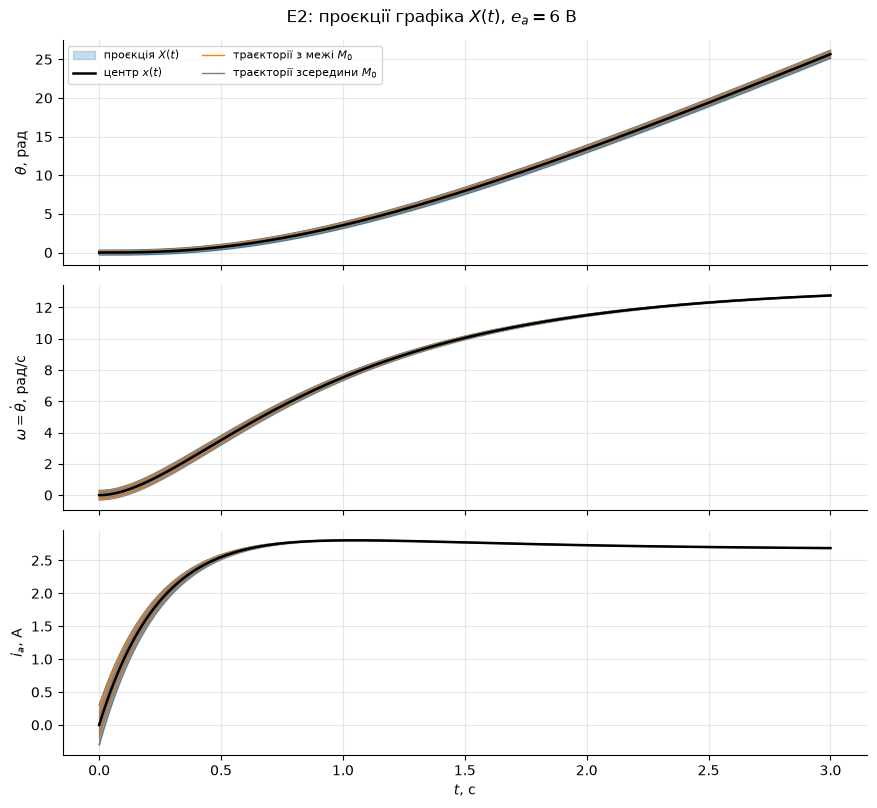

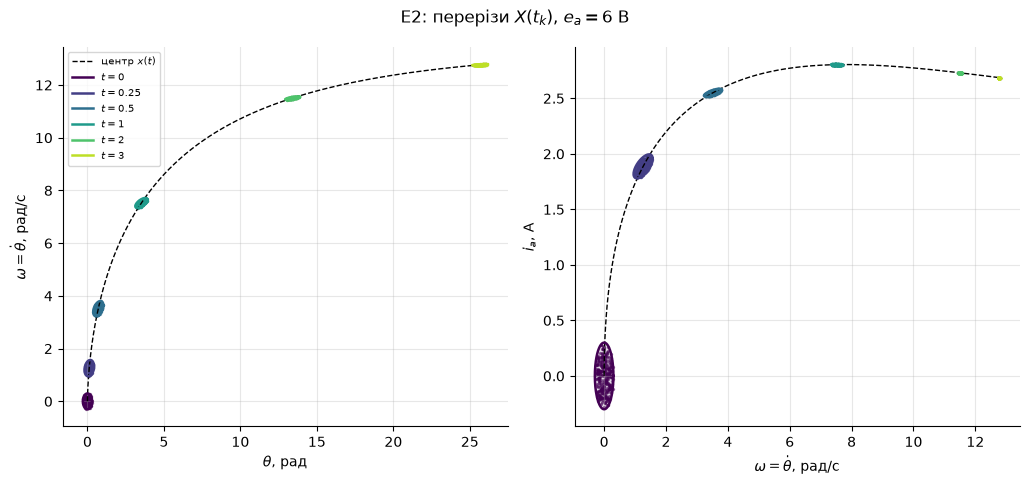

In [13]:
E2 = 6.0
step = lambda t: E2
x0_e2 = [0.0, 0.0, 0.0]
s2, c2, r2 = run("Е2. Сталий вхід (P1, ea = 6 В)", PARAMS["P1"], step, x0_e2, Q0_ball,
                 T1, times1, rng)
dQ12 = float(np.max(np.abs(s1["Q"] - s2["Q"])))
w_inf = MODEL["P1"]["speed_gain"] * E2
i_inf = MODEL["P1"]["current_gain"] * E2
print(f"  max |Q_Е1(t) - Q_Е2(t)| = {dQ12:.1e};  ω∞ = {w_inf:.4f} рад/с, i∞ = {i_inf:.4f} А, "
      f"ω(T) = {s2['x'][-1, 1]:.4f}, i(T) = {s2['x'][-1, 2]:.4f}")
plot_bands(s2, c2, "e2_bands.png", r"Е2: проєкції графіка $X(t)$, $e_a = 6$ В")
plot_sections(s2, c2, times1, [(0, 1), (1, 2)], "e2_sections.png",
              r"Е2: перерізи $X(t_k)$, $e_a = 6$ В")

### Е3. Знакозмінна напруга $e_a=6\sin 2\pi t$, недіагональна $Q_0$

Привід «гойдають» реверсивною напругою. Кут вимірюється енкодером точно ($\sqrt{Q_{0,11}}=0.05$), а швидкість і струм відомі гірше й корельовані (коефіцієнт кореляції $0.6$): $Q_0=DCD$.

In [14]:
E3, nu = 6.0, 1.0  # амплітуда, В; частота, Гц
sine = lambda t: E3 * np.sin(2 * np.pi * nu * t)
std3 = [0.05, 0.6, 0.4]  # кут відомий точно, швидкість і струм — гірше
corr3 = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.6], [0.0, 0.6, 1.0]]
Q0_e3 = cov_matrix(std3, corr3)
x0_e3 = [0.0, 0.0, 0.0]
T3, times3 = 3.0, [0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
s3, c3, r3 = run("Е3. ea = 6 sin(2πt) (P1, Q0 недіагональна)", PARAMS["P1"], sine, x0_e3,
                 Q0_e3, T3, times3, rng)


Е3. ea = 6 sin(2πt) (P1, Q0 недіагональна):  T = 3.0, nfev = 1982
    t |            центр x(t)            |             півосі             |     det Q
 0.00 |     0.0000     0.0000     0.0000 |  6.60e-01  2.91e-01  5.00e-02 |  9.22e-05
 0.25 |     0.0443     0.6356     1.3615 |  6.90e-01  8.64e-02  4.61e-02 |  7.56e-06
 0.50 |     0.4284     2.3989     1.5150 |  6.69e-01  6.08e-02  1.94e-02 |  6.21e-07
 0.75 |     1.0718     2.2419    -0.8482 |  6.54e-01  5.52e-02  6.25e-03 |  5.10e-08
 1.00 |     1.3754     0.1642    -1.3692 |  6.66e-01  4.54e-02  2.14e-03 |  4.18e-09
 1.50 |     1.4664     1.4407     1.3473 |  7.28e-01  2.56e-02  2.85e-04 |  2.82e-11
 2.00 |     1.9922    -0.5229    -1.3747 |  7.86e-01  1.36e-02  4.08e-05 |  1.90e-13
 3.00 |     2.1865    -0.7507    -1.3673 |  8.47e-01  3.93e-03  8.83e-07 |  8.62e-18
  (a) max ||Q - ΘQ0Θ*|| / ||ΘQ0Θ*||            = 9.7e-13
  (b) відн. похибка det Q (Ліувілль): max 1.1e-08, при t = T 1.6e-09 (cond Q(T) = 9.2e+11)
  (c) max |x(t) - x

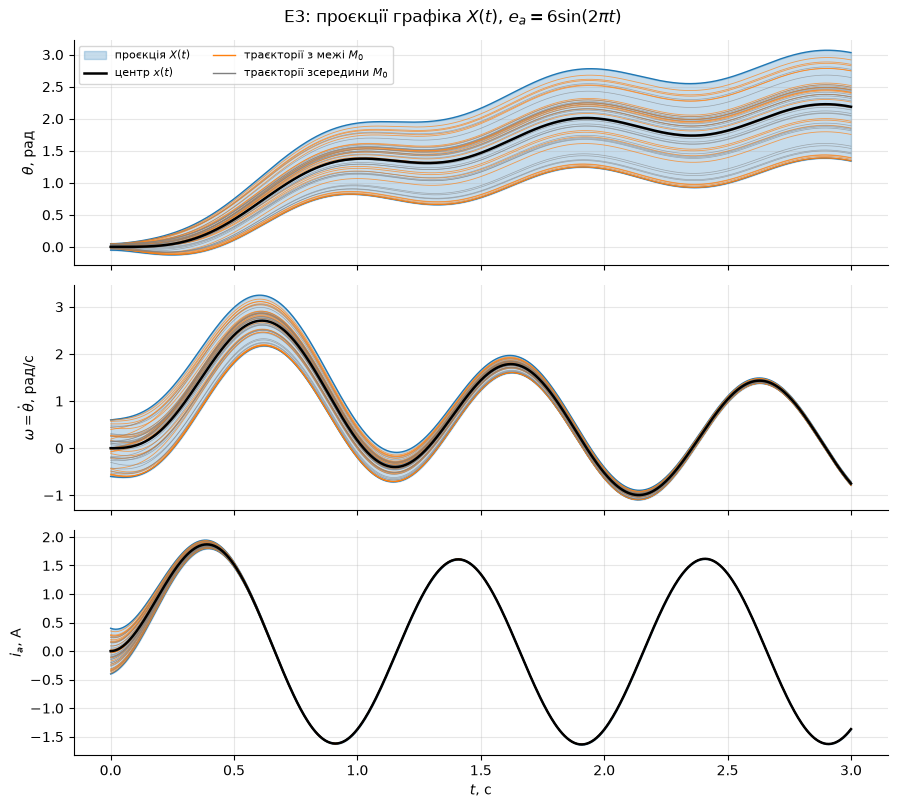

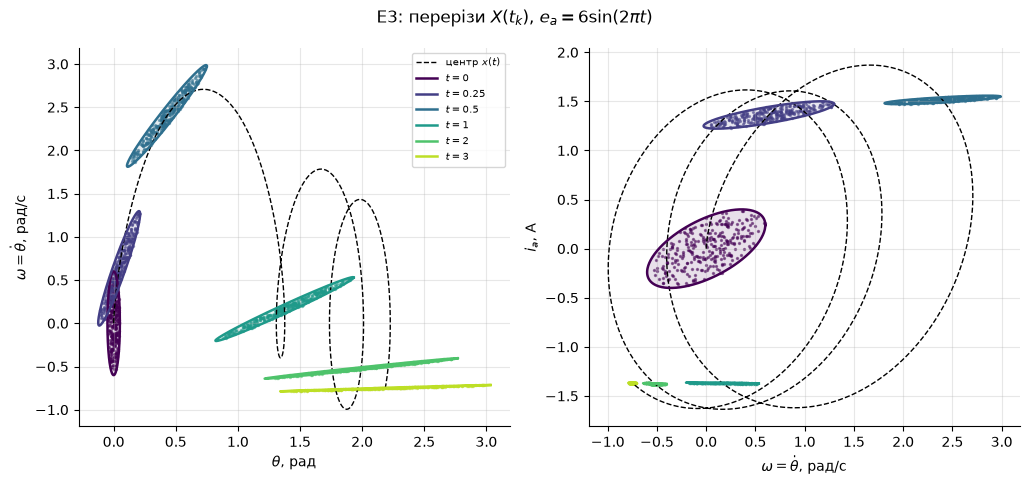

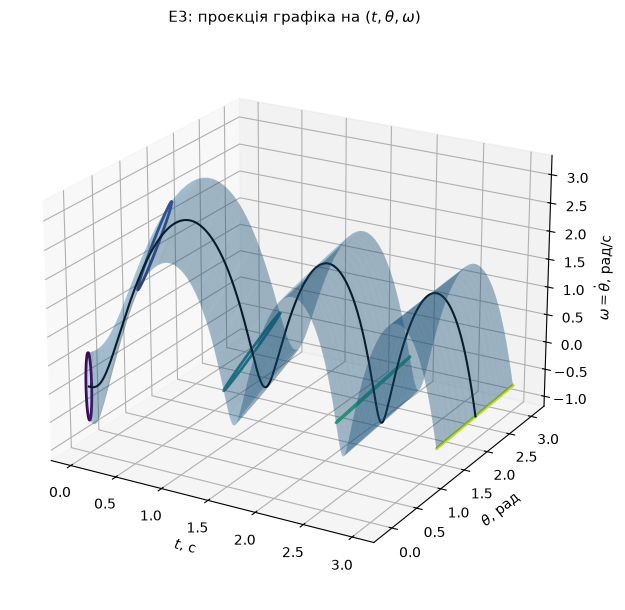

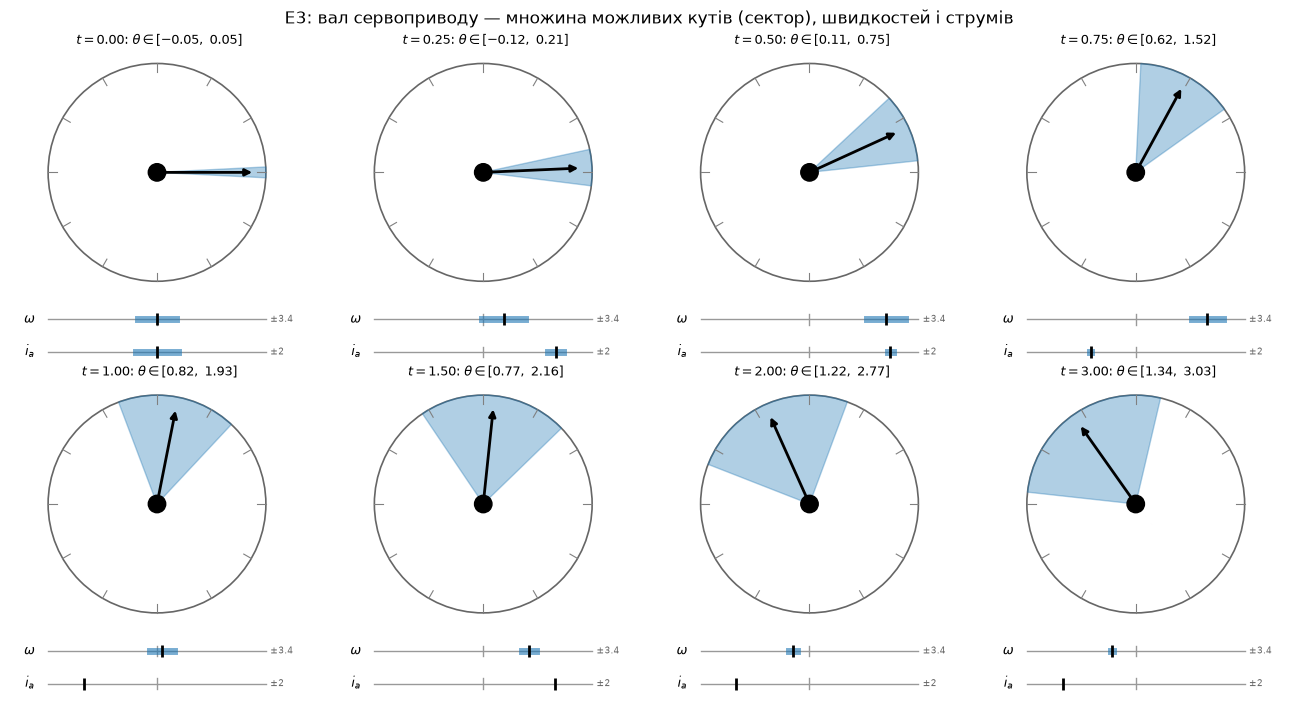

In [15]:
plot_bands(s3, c3, "e3_bands.png", r"Е3: проєкції графіка $X(t)$, $e_a = 6\sin(2\pi t)$")
plot_sections(s3, c3, [0.0, 0.25, 0.5, 1.0, 2.0, 3.0], [(0, 1), (1, 2)], "e3_sections.png",
              r"Е3: перерізи $X(t_k)$, $e_a = 6\sin(2\pi t)$")
plot_tube(s3, 0, 1, [0.0, 0.5, 1.0, 2.0, 3.0], "e3_tube.png",
          r"Е3: проєкція графіка на $(t, \theta, \omega)$")
plot_shaft_frames(s3, times3, "e3_shaft.png",
                  "Е3: вал сервоприводу — множина можливих кутів (сектор), швидкостей і струмів")

### Е4. Вплив параметрів: P1 (дійсні власні числа) проти P2 (комплексні)

Вільний вибіг з $x_0=(0,5,0)$, $Q_0=0.3^2I$, $T=4$ с. Для P2 центр у площині $(\omega,i_a)$ іде по загасаючій спіралі, а переріз обертається.


Е4а. Вільний вибіг, P1:  T = 4.0, nfev = 1406
    t |            центр x(t)            |             півосі             |     det Q
 0.00 |     0.0000     5.0000     0.0000 |  3.00e-01  3.00e-01  3.00e-01 |  7.29e-04
 0.50 |     1.9416     2.9119    -0.0770 |  3.75e-01  2.35e-01  2.52e-02 |  4.91e-06
 1.00 |     3.0498     1.6367    -0.0541 |  4.19e-01  1.38e-01  3.14e-03 |  3.31e-08
 1.50 |     3.6694     0.9115    -0.0317 |  4.56e-01  7.39e-02  4.43e-04 |  2.23e-10
 2.00 |     4.0141     0.5065    -0.0179 |  4.83e-01  3.93e-02  6.47e-05 |  1.50e-12
 3.00 |     4.3118     0.1561    -0.0055 |  5.09e-01  1.15e-02  1.41e-06 |  6.82e-17
 4.00 |     4.4036     0.0481    -0.0017 |  5.18e-01  3.49e-03  3.08e-08 |  3.10e-21
  (a) max ||Q - ΘQ0Θ*|| / ||ΘQ0Θ*||            = 2.9e-13
  (b) відн. похибка det Q (Ліувілль): max 7.5e-07, при t = T 2.6e-07 (cond Q(T) = 2.8e+14)
  (c) max |x(t) - x_окремо(t)|                 = 3.6e-13
  (d) 300 траєкторій зсередини M0: max <Q^-1 d, d> = 0.999207;  з м

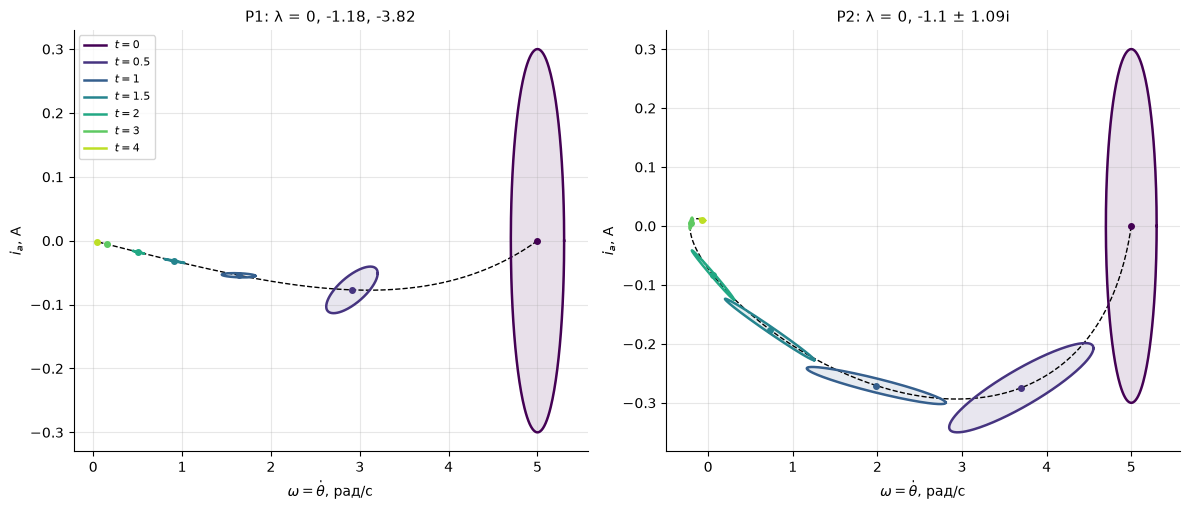

In [16]:
T4, times4 = 4.0, [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
x0_e4 = [0.0, 5.0, 0.0]
s4a, c4a, r4a = run("Е4а. Вільний вибіг, P1", PARAMS["P1"], zero, x0_e4, Q0_ball, T4, times4, rng)
s4b, c4b, r4b = run("Е4б. Вільний вибіг, P2", PARAMS["P2"], zero, x0_e4, Q0_ball, T4, times4, rng)
plot_compare_params([("P1: λ = 0, -1.18, -3.82", s4a), ("P2: λ = 0, -1.1 ± 1.09i", s4b)],
                    times4, "e4_compare.png")

### Граничний стан при $e_a=0$ (перевірка (e))

$e^{At}\to e_1w^*$, тому вал зупиниться на куті $\theta_\infty=\langle w,x_0\rangle$, а пучок стиснеться у відрізок уздовж $\theta$:
$Q(\infty)=\langle Q_0w,w\rangle\,e_1e_1^*$, півширина $\sqrt{\langle Q_0w,w\rangle}$.

In [17]:
def limit(key, x0, Q0, sol):
    # граничний стан при ea = 0: θ(∞) = <w, x0>, sqrt(Q11(∞)) = sqrt(<Q0 w, w>)
    w = np.array(MODEL[key]["w"])
    lim = {"theta_inf": float(w @ np.asarray(x0)), "half_inf": float(np.sqrt(w @ Q0 @ w)),
           "theta_T": float(sol["x"][-1, 0]), "half_T": float(np.sqrt(sol["Q"][-1, 0, 0]))}
    print(f"  {key}: θ(∞) = {lim['theta_inf']:.4f} (θ(T) = {lim['theta_T']:.4f}),  "
          f"sqrt(Q11(∞)) = {lim['half_inf']:.4f} (при t = T: {lim['half_T']:.4f})")
    return lim


lim1 = limit("P1", x0_e1, Q0_ball, s1)
lim4a = limit("P1", x0_e4, Q0_ball, s4a)
lim4b = limit("P2", x0_e4, Q0_ball, s4b)

  P1: θ(∞) = 4.4444 (θ(T) = 4.3118),  sqrt(Q11(∞)) = 0.5217 (при t = T: 0.5088)
  P1: θ(∞) = 4.4444 (θ(T) = 4.4036),  sqrt(Q11(∞)) = 0.5217 (при t = T: 0.5177)
  P2: θ(∞) = 4.1667 (θ(T) = 4.1797),  sqrt(Q11(∞)) = 1.3096 (при t = T: 1.3286)


### Об'єм пучка: формула Ліувілля

$\det Q(t)=\det Q_0\,e^{2t\operatorname{tr}A}$, отже $\operatorname{vol}X(t)=\operatorname{vol}M_0\,e^{t\operatorname{tr}A}$ спадає (система дисипативна).
Праворуч видно, що відносна похибка $\det Q$ росте разом з $\operatorname{cond}Q(t)$: це втрата точності найменшої півосі при сплющенні, а не похибка методу.

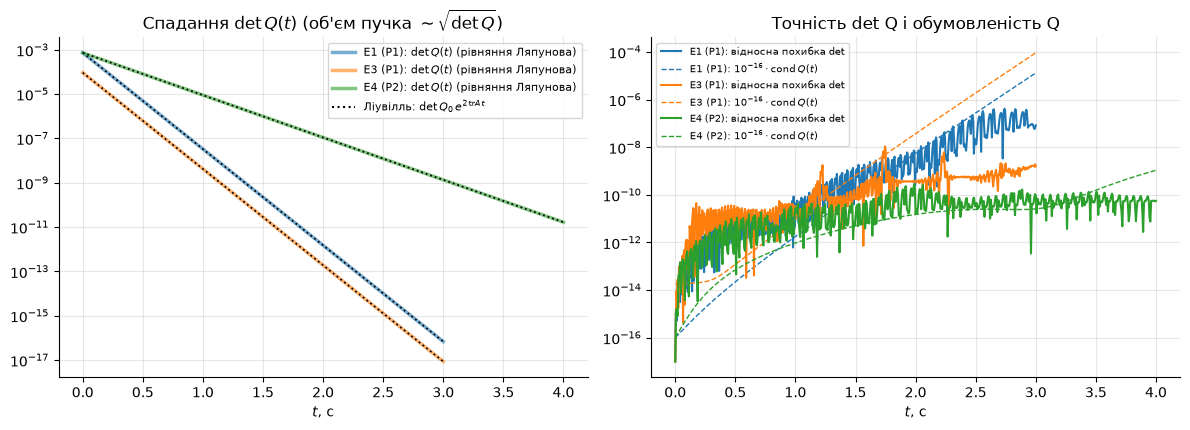

In [18]:
plot_det([("Е1 (P1)", s1, c1), ("Е3 (P1)", s3, c3), ("Е4 (P2)", s4b, c4b)], "det_liouville.png")

### Збереження результатів для звіту

Звіт `report/report.typ` читає всі числа з `report/figures/results.json`.

In [19]:
OUT["e1"] = {"x0": x0_e1, "Q0": Q0_ball.tolist(), "T": T1, "rows": r1, "checks": public(c1),
             "limit": lim1}
OUT["e2"] = {"x0": x0_e2, "Q0": Q0_ball.tolist(), "T": T1, "ea": E2, "rows": r2,
             "checks": public(c2), "dQ_e1_e2": dQ12, "w_inf": w_inf, "i_inf": i_inf}
OUT["e3"] = {"x0": x0_e3, "Q0": Q0_e3.tolist(), "std": std3, "corr": corr3, "T": T3,
             "amp": E3, "freq": nu, "rows": r3, "checks": public(c3)}
OUT["e4"] = {"x0": x0_e4, "Q0": Q0_ball.tolist(), "T": T4,
             "P1": {"rows": r4a, "checks": public(c4a), "limit": lim4a},
             "P2": {"rows": r4b, "checks": public(c4b), "limit": lim4b}}
with open(os.path.join(FIG_DIR, "results.json"), "w", encoding="utf-8") as fp:
    json.dump(OUT, fp, ensure_ascii=False, indent=1)
print("збережено", os.path.relpath(os.path.join(FIG_DIR, "results.json")))

збережено report/figures/results.json


### Анімація (Е3)

Ліворуч вал із сектором можливих кутів, у центрі переріз $X(t)$ у площині $(\theta,\omega)$, праворуч смуга $\theta(t)\pm\sqrt{Q_{11}}$ і напруга $e_a(t)$.

In [20]:
make_shaft_animation(s3, sine, "e3_shaft_anim")
display(Video(os.path.join("report", "figures", "e3_shaft_anim.mp4"), width=900))

  збережено e3_shaft_anim.gif / e3_shaft_anim.mp4
